In [1]:
import sys
sys.path.append("..")

from src.data import load_events, add_xy, filter_events
from src.features import *
from src.viz import *
import matplotlib.pyplot as plt


pitch = VerticalPitch(half=True, pitch_type="statsbomb", line_color="#444")
events = add_xy(load_events(18245))
match_summary(events)

,shots,on_target,goals,xg,shot_accuracy_%,shot_share_%,passes,completed,pass_accuracy_%,pass_share_%
team,,,,,,,,,,
Liverpool,14,3,1,1.43,21.4,50.0,360,266,73.9,34.8
Real Madrid,14,6,3,1.68,42.9,50.0,673,596,88.6,65.2


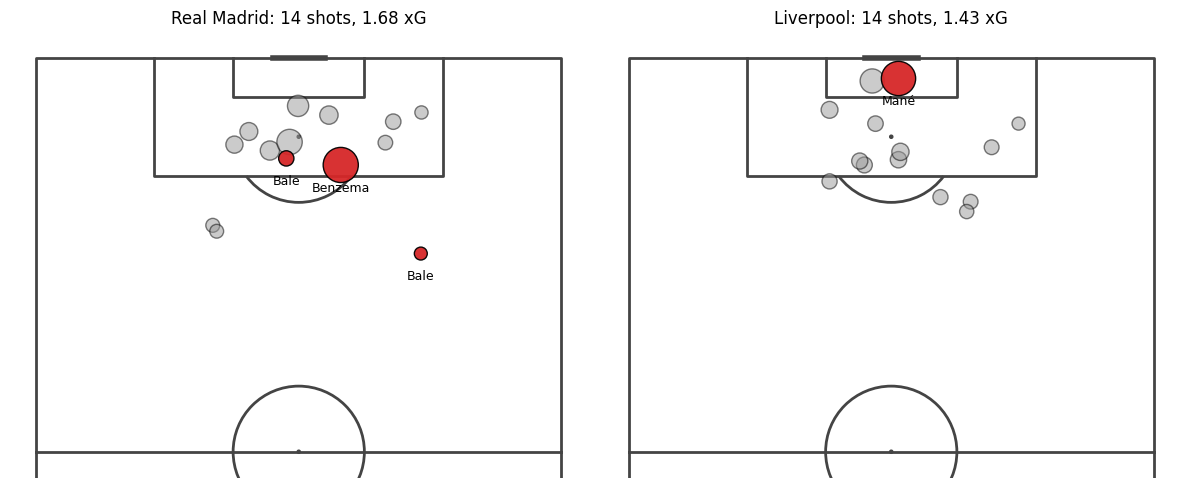

In [4]:
shots = filter_events(regular_play(events), "Shot")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, team in zip(axes, get_teams(events)):
    plot_shot_map(shots, team, ax=ax)
plt.tight_layout()
fig.savefig("../outputs/figures/shot_maps.png", dpi=150, bbox_inches="tight")

In [10]:
from src.features import passing_network
from src.viz import plot_pass_network

nodes, edges = passing_network(events, "Liverpool", min_passes=2)
nodes.sort_values("passes", ascending=False)     # who touched the ball most?

,x,y,passes
player,,,
Jordan Brian Henderson,61.035294,37.152941,17
James Philip Milner,72.353333,36.153333,15
Andrew Robertson,59.815385,6.830769,13
Trent Alexander-Arnold,64.666667,72.550000,12
Dejan Lovren,41.690909,60.172727,11
Georginio Wijnaldum,76.390909,28.518182,11
Mohamed Salah,77.550000,64.710000,10
Roberto Firmino Barbosa de Oliveira,78.250000,43.570000,10
Virgil van Dijk,43.366667,25.433333,9


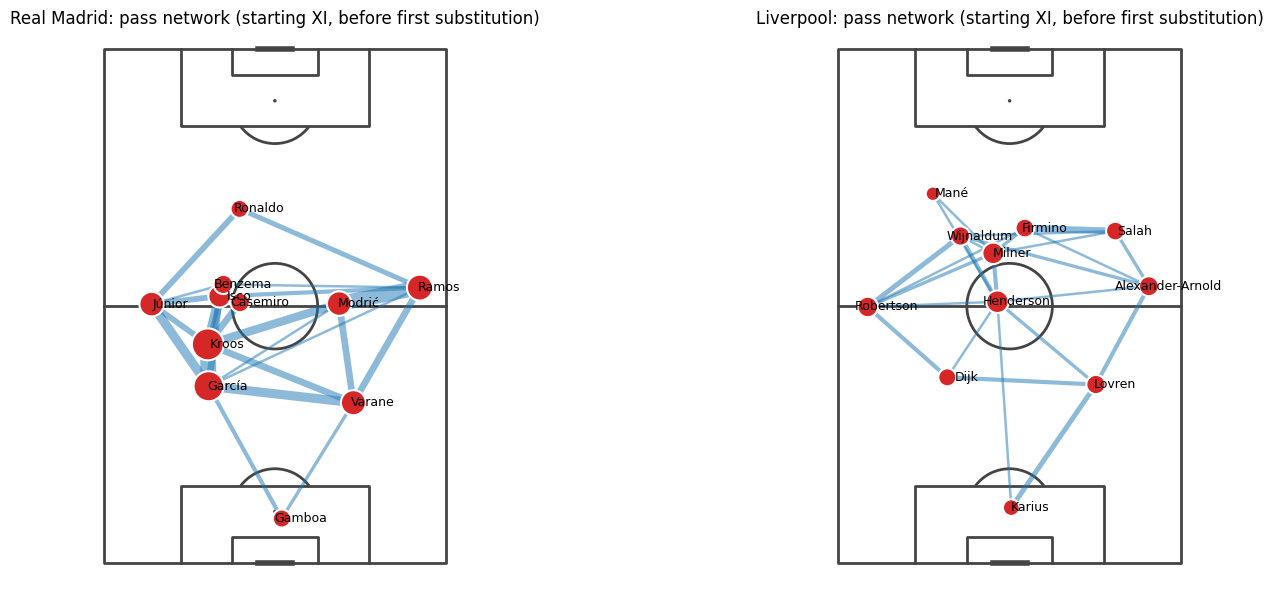

In [11]:
# StatsBomb uses full legal names, so the default label can be wrong
pitch = VerticalPitch(half=False, pitch_type="statsbomb", line_color="#444")
labels = {
    "Roberto Firmino Barbosa de Oliveira": "Firmino",
    "Francisco Román Alarcón Suárez": "Isco",
    "Cristiano Ronaldo dos Santos Aveiro": "Ronaldo",
    "Carlos Henrique Casimiro": "Casemiro",
}

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, team in zip(axes, get_teams(events)):
    nodes, edges = passing_network(events, team)
    plot_pass_network(pitch,nodes, edges, team, labels=labels, ax=ax)
plt.tight_layout()
fig.savefig("../outputs/figures/pass_networks.png", dpi=150, bbox_inches="tight")

In [3]:
pressing_summary(events)

,pressures,opp_half_%,final_third_%
team,,,
Liverpool,134,46.3,16.4
Real Madrid,92,39.1,15.2


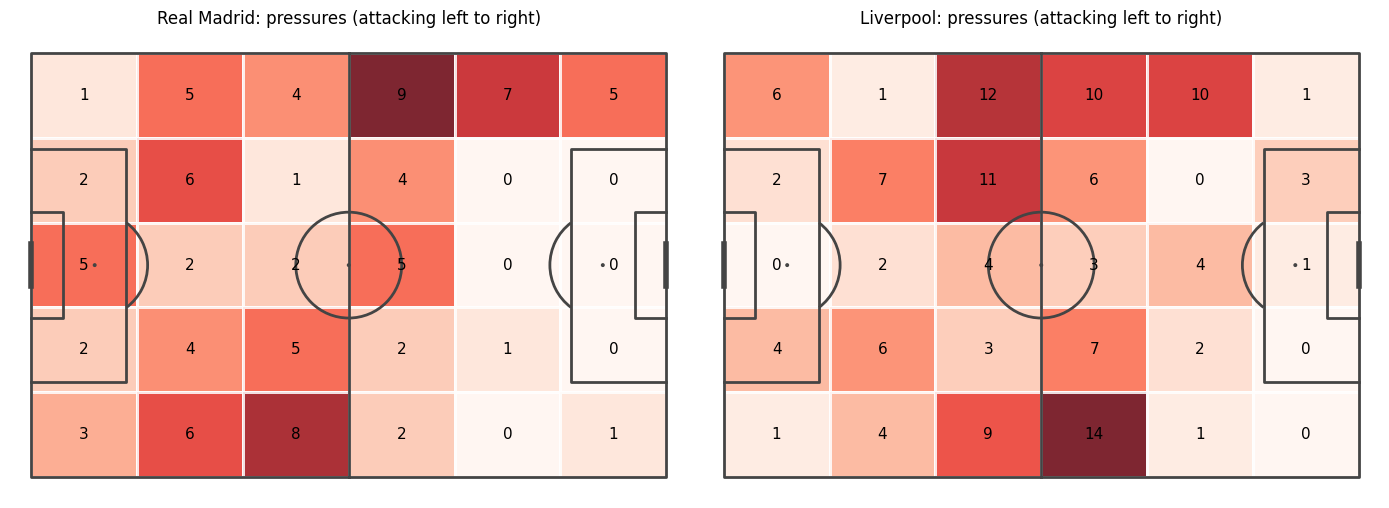

In [2]:
pitch = Pitch(half=False, pitch_type="statsbomb", line_color="#444", line_zorder=3)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, team in zip(axes, get_teams(events)):
    pressures = event_locations(events, ["Pressure"], team)
    plot_heatmap(pressures, pitch, f"{team}: pressures (attacking left to right)", ax=ax)
plt.tight_layout()
fig.savefig("../outputs/figures/pressing_zones.png", dpi=150, bbox_inches="tight")